In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from data_preprocessing import load_data, clean_data, encode_data

In [2]:
train_raw = load_data('../data/KDDTrain+.txt')
test_raw = load_data('../data/KDDTest+.txt')

print(train_raw.shape, test_raw.shape)
train_raw.head()

(125973, 43) (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [3]:
train_raw.info()
train_raw.isnull().sum().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  object 
 2   service                      125973 non-null  object 
 3   flag                         125973 non-null  object 
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13 

np.int64(0)

In [4]:
train_raw['attack'].value_counts().head(10)

attack
normal         67343
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
Name: count, dtype: int64

label
0    67343
1    58630
Name: count, dtype: int64


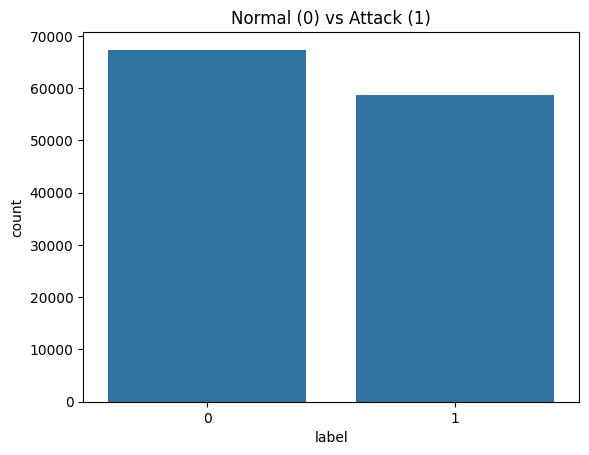

In [5]:
train_df = clean_data(train_raw)
test_df = clean_data(test_raw)

print(train_df['label'].value_counts())

sns.countplot(data=train_df, x='label')
plt.title('Normal (0) vs Attack (1)')
plt.show()

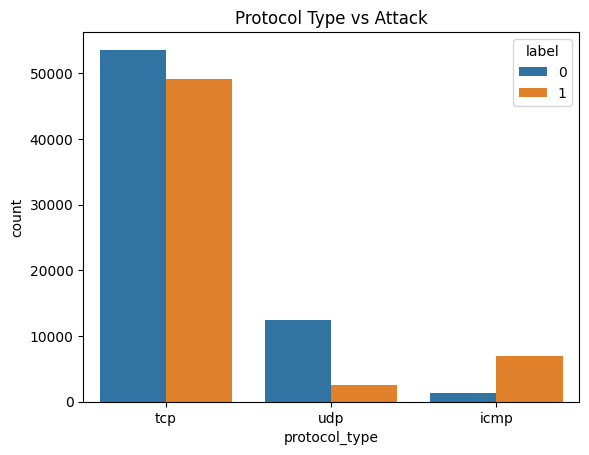

In [6]:
sns.countplot(data=train_df, x='protocol_type', hue='label')
plt.title('Protocol Type vs Attack')
plt.show()

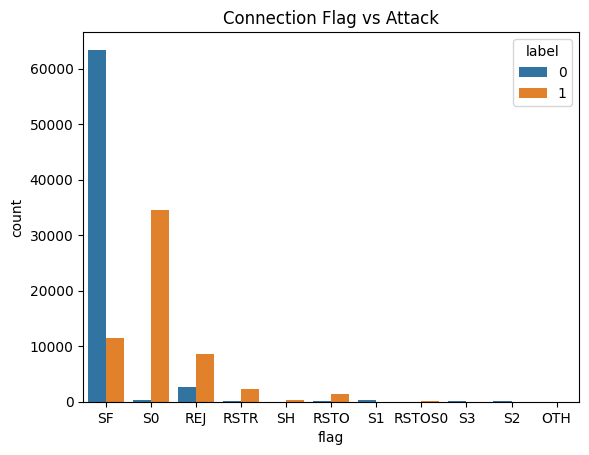

In [7]:
sns.countplot(data=train_df, x='flag', hue='label')
plt.title('Connection Flag vs Attack')
plt.show()

In [8]:
train_enc = encode_data(train_df)
test_enc = encode_data(test_df)
test_enc = test_enc.reindex(columns=train_enc.columns, fill_value=0)

X_train = train_enc.drop('label', axis=1)
y_train = train_enc['label']
X_test = test_enc.drop('label', axis=1)
y_test = test_enc['label']

print(X_train.shape, X_test.shape)

(125973, 122) (22544, 122)


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

dt_model = DecisionTreeClassifier(max_depth=15, random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
print(classification_report(y_test, dt_pred, target_names=['Normal', 'Attack']))

              precision    recall  f1-score   support

      Normal       0.67      0.96      0.79      9711
      Attack       0.96      0.65      0.77     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.80      0.78     22544
weighted avg       0.84      0.78      0.78     22544



In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
print(classification_report(y_test, rf_pred, target_names=['Normal', 'Attack']))

              precision    recall  f1-score   support

      Normal       0.66      0.97      0.78      9711
      Attack       0.97      0.62      0.75     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.79      0.77     22544
weighted avg       0.83      0.77      0.77     22544



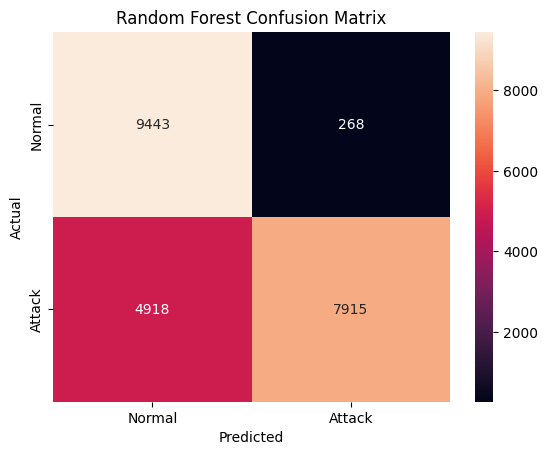

In [11]:
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

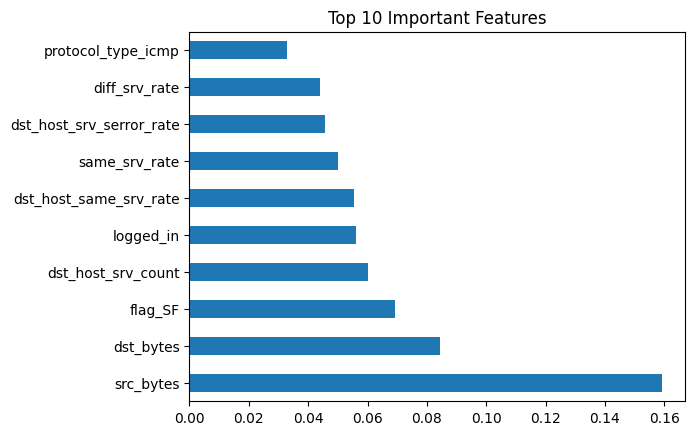

In [12]:
importance = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importance.sort_values(ascending=False).head(10).plot(kind='barh')
plt.title('Top 10 Important Features')
plt.show()